# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Rushil Nanga, Claire Curzan, Ashley Tibebe, Shravya Etta

**Date:** 11/18/2026

**Q1**

In [ ]:
%pip install numpy pandas matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


(16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric                      2
Floor Wall Furnace            1
Name: count, dtype: int64
exterior
Frame Siding              14577
Frame Vinyl                1724
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5
Unfinished Cottage            4
Pine Finished Cabin           4
Cedar A-Frame                 2
Cedar Unfinished Cabin        2
Pine Unfinished Cabin         2
NaN                           1
Pine A-Frame                  1
Name: count, dtype: int64
interior
Drywall     16777
Paneling       30
NaN          

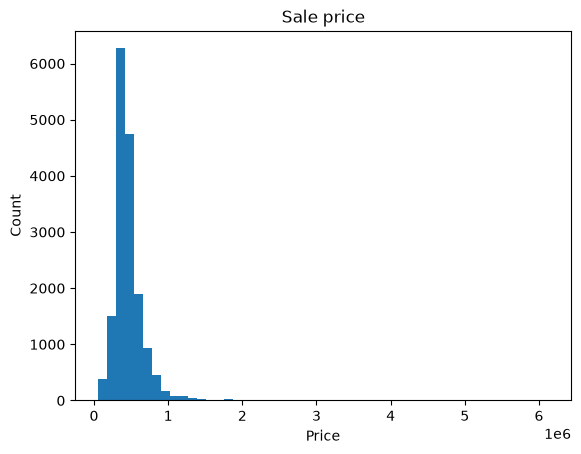

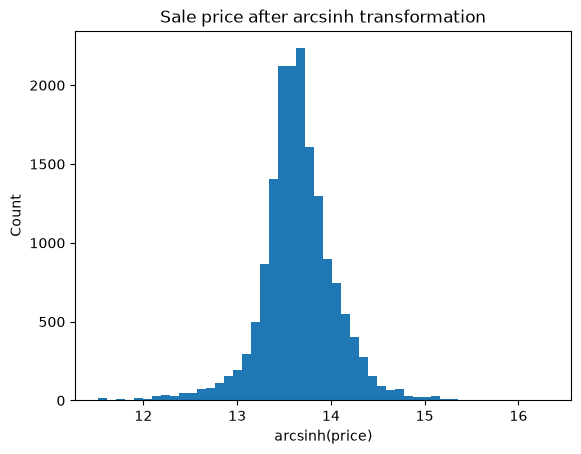

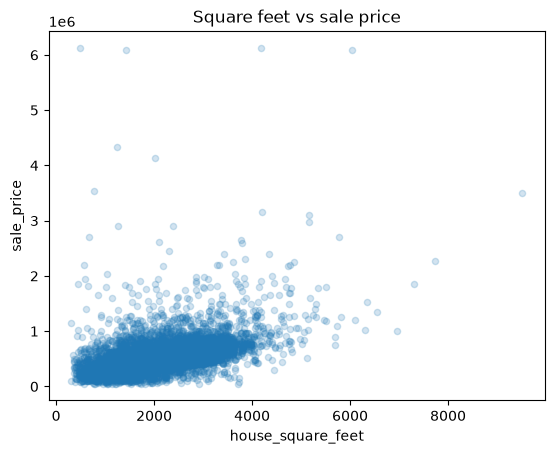

sale_price                     1.00
house_square_feet              0.54
bathrooms                      0.42
fireplaces                     0.35
attached_garage_square_feet    0.32
basement_square_feet           0.27
year_built                     0.23
bedrooms                       0.22
stories                        0.17
detached_garage_square_feet    0.05
attic_finished_square_feet     0.02
Name: sale_price, dtype: float64
view_quality
None            410000.0
View Lim -      575000.0
View Lim        600000.0
View Avg        677250.0
View Lim +      699000.0
View Avg +      799975.0
View Good       800000.0
View Good +     856250.0
View V-Good    1142000.0
Name: sale_price, dtype: float64


In [ ]:
# Your Phase 1 solution to the problem goes here.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Q1
sales_df = pd.read_csv("pierce_county_house_sales.csv")

print(sales_df.shape)
display(sales_df.head())
sales_df.info()
print(sales_df.isna().sum())
display(sales_df.describe())

# Look at categorical columns
print(sales_df["hvac_description"].value_counts(dropna=False))
print(sales_df["exterior"].value_counts(dropna=False))
print(sales_df["interior"].value_counts(dropna=False))
print(sales_df["roof_cover"].value_counts(dropna=False))
print(sales_df["waterfront_type"].value_counts(dropna=False))
print(sales_df["view_quality"].value_counts(dropna=False))
print(sales_df["utility_sewer"].value_counts(dropna=False))

# Standardize names
sales_df["waterfront_type"] = sales_df["waterfront_type"].fillna("None")
sales_df["view_quality"] = sales_df["view_quality"].fillna("None")
sales_df["hvac_description"] = sales_df["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# Drop missing rows
sales_df = sales_df.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"])
sales_df["sale_date"] = pd.to_datetime(sales_df["sale_date"])

print(sales_df.sort_values("sale_price").head(10))
print(sales_df.sort_values("house_square_feet").head(10))
print(sales_df["bedrooms"].value_counts())
print(sales_df["bathrooms"].value_counts())
print(sales_df["stories"].value_counts())

# Drop rows that don't make sense
sales_df = sales_df.query("sale_price >= 50000")
sales_df = sales_df.query("house_square_feet >= 300")
sales_df = sales_df.query("bedrooms <= 10")
sales_df = sales_df.query("stories > 0")
sales_df = sales_df.query("bathrooms > 0")
print(sales_df.shape)

# Histogram of sale price
sales_df["sale_price"].hist(bins=50, grid=False)
plt.title("Sale price")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# Transformed because of long right tail
sales_df["price_arcsinh"] = np.arcsinh(sales_df["sale_price"])
sales_df["price_arcsinh"].hist(bins=50, grid=False)
plt.title("Sale price after arcsinh transformation")
plt.xlabel("arcsinh(price)")
plt.ylabel("Count")
plt.show()

# Square feet vs price
sales_df.plot.scatter(x="house_square_feet", y="sale_price", alpha=0.2)
plt.title("Square feet vs sale price")
plt.show()

# Correlations with price
numeric_cols = ["sale_price", "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
                "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
                "stories", "year_built", "bedrooms", "bathrooms"]
print(sales_df[numeric_cols].corr()["sale_price"].sort_values(ascending=False).round(2))

# Median price
print(sales_df.groupby("view_quality")["sale_price"].median().sort_values())

# Month column to help with later questions
sales_df["month"] = sales_df["sale_date"].dt.month

**Q2**

In [ ]:
# Q2
# Assign numbers to view_quality
view_scores = {"None": 0, "View Lim -": 1, "View Lim": 2, "View Lim +": 3, "View Avg": 4,
               "View Avg +": 5, "View Good": 6, "View Good +": 7, "View V-Good": 8}
sales_df["view_score"] = sales_df["view_quality"].map(view_scores)

# Make interior and sewer a 0 or 1 variable because both are mostly same value
sales_df["paneling"] = (sales_df["interior"] == "Paneling").astype(int)
sales_df["sewer_installed"] = (sales_df["utility_sewer"] == "SEWER/SEPTIC INSTALLED").astype(int)

# Combine small categories
sales_df["hvac"] = sales_df["hvac_description"].replace("Electric", "Electric Baseboard")
sales_df["ext"] = sales_df["exterior"]
small_exteriors = sales_df["ext"].value_counts()[sales_df["ext"].value_counts() < 50].index
sales_df["ext"] = sales_df["ext"].replace(list(small_exteriors), "Other")
print(sales_df["hvac"].value_counts(), '\n')
print(sales_df["ext"].value_counts(), '\n')

# One-hot encode categorical variables
df_water = pd.get_dummies(sales_df["waterfront_type"], prefix="wf", drop_first=True, dtype=int)
df_hvac = pd.get_dummies(sales_df["hvac"], prefix="hvac", drop_first=True, dtype=int)
df_ext = pd.get_dummies(sales_df["ext"], prefix="ext", drop_first=True, dtype=int)
df_roof = pd.get_dummies(sales_df["roof_cover"], prefix="roof", drop_first=True, dtype=int)

numeric_vars = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
                "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
                "stories", "year_built", "bedrooms", "bathrooms"]
other_vars = ["view_score", "paneling", "sewer_installed", "month"]

X = pd.concat([sales_df[numeric_vars + other_vars], df_water, df_hvac, df_ext, df_roof], axis=1)
y = sales_df["sale_price"]

print("X shape:", X.shape)
display(X.head())

hvac
Forced Air                10346
Electric Baseboard         2645
Heat Pump                  2069
Warm and Cool Air Zone     1262
Floor/Wall Furnace          171
Hot Water Baseboard         146
No Heat                      64
Name: count, dtype: int64 

ext
Frame Siding            14507
Frame Vinyl              1715
Masonry Common Brick      208
Frame Stucco              156
Other                     117
Name: count, dtype: int64 

X shape: (16703, 33)


,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,hvac_Warm and Cool Air Zone,ext_Frame Stucco,ext_Frame Vinyl,ext_Masonry Common Brick,ext_Other,roof_Composition Shingle,roof_Concrete Tile,roof_Formed Seam Metal,roof_Preformed Metal,roof_Wood Shake
0,2157,0,0,528,0,0,2,1993,3,3,...,1,0,0,0,0,1,0,0,0,0
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,1,0,0,0,0
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,0,0,0
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,1,0,0,1,0,0,0,0
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,1,0,0,0,0


**Q3**

In [ ]:
# Q3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (13362, 33)  Test: (3341, 33)


**Q4**

In [ ]:
# Q4
water_vars = list(df_water.columns)

model_features = {
    "M1: sqft": ["house_square_feet"],
    "M2: sqft + beds + baths": ["house_square_feet", "bedrooms", "bathrooms"],
    "M3: all numeric": numeric_vars,
    "M4: numeric + waterfront/view/month": numeric_vars + water_vars + ["view_score", "month"],
    "M5: everything": list(X.columns),
}

model_names = []
train_rmse = []
test_rmse = []
train_rsq = []
test_rsq = []

for name, features in model_features.items():
    reg = LinearRegression().fit(X_train[features], y_train)

    train_hat = reg.predict(X_train[features])
    test_hat = reg.predict(X_test[features])

    model_names.append(name)
    train_rmse.append(np.sqrt(np.mean((y_train - train_hat) ** 2)))
    test_rmse.append(np.sqrt(np.mean((y_test - test_hat) ** 2)))
    train_rsq.append(reg.score(X_train[features], y_train))
    test_rsq.append(reg.score(X_test[features], y_test))

results = pd.DataFrame({
    "train RMSE": train_rmse,
    "test RMSE": test_rmse,
    "train R2": train_rsq,
    "test R2": test_rsq,
}, index=model_names)
display(results.round(3))

,train RMSE,test RMSE,train R2,test R2
M1: sqft,205050.796,160980.155,0.268,0.389
M2: sqft + beds + baths,202123.361,158617.889,0.288,0.407
M3: all numeric,186606.935,139452.492,0.393,0.542
M4: numeric + waterfront/view/month,167128.436,121088.559,0.513,0.655
M5: everything,165265.820,119882.720,0.524,0.661


Q4 Written: Which model does the best?
The M5 (all features) model does the best. It has the lowest test RMSE (about $119,900) and the highest test R^2 (0.661), so it explains about 66% of the variation in sale prices for houses it never saw during training.

That being said however, the M4 model is almost as good (test RMSE about $121,100, test R^2 0.655) with about half as many features. Most of the improvement comes from going M3 to M4, which adds waterfront, view and month. Test R^2 jumps from 0.54 to 0.66 there, so location and amenities matter much more than the building details added in M5 (heating, exterior and roof type), which only add about 0.006.

**Q5**

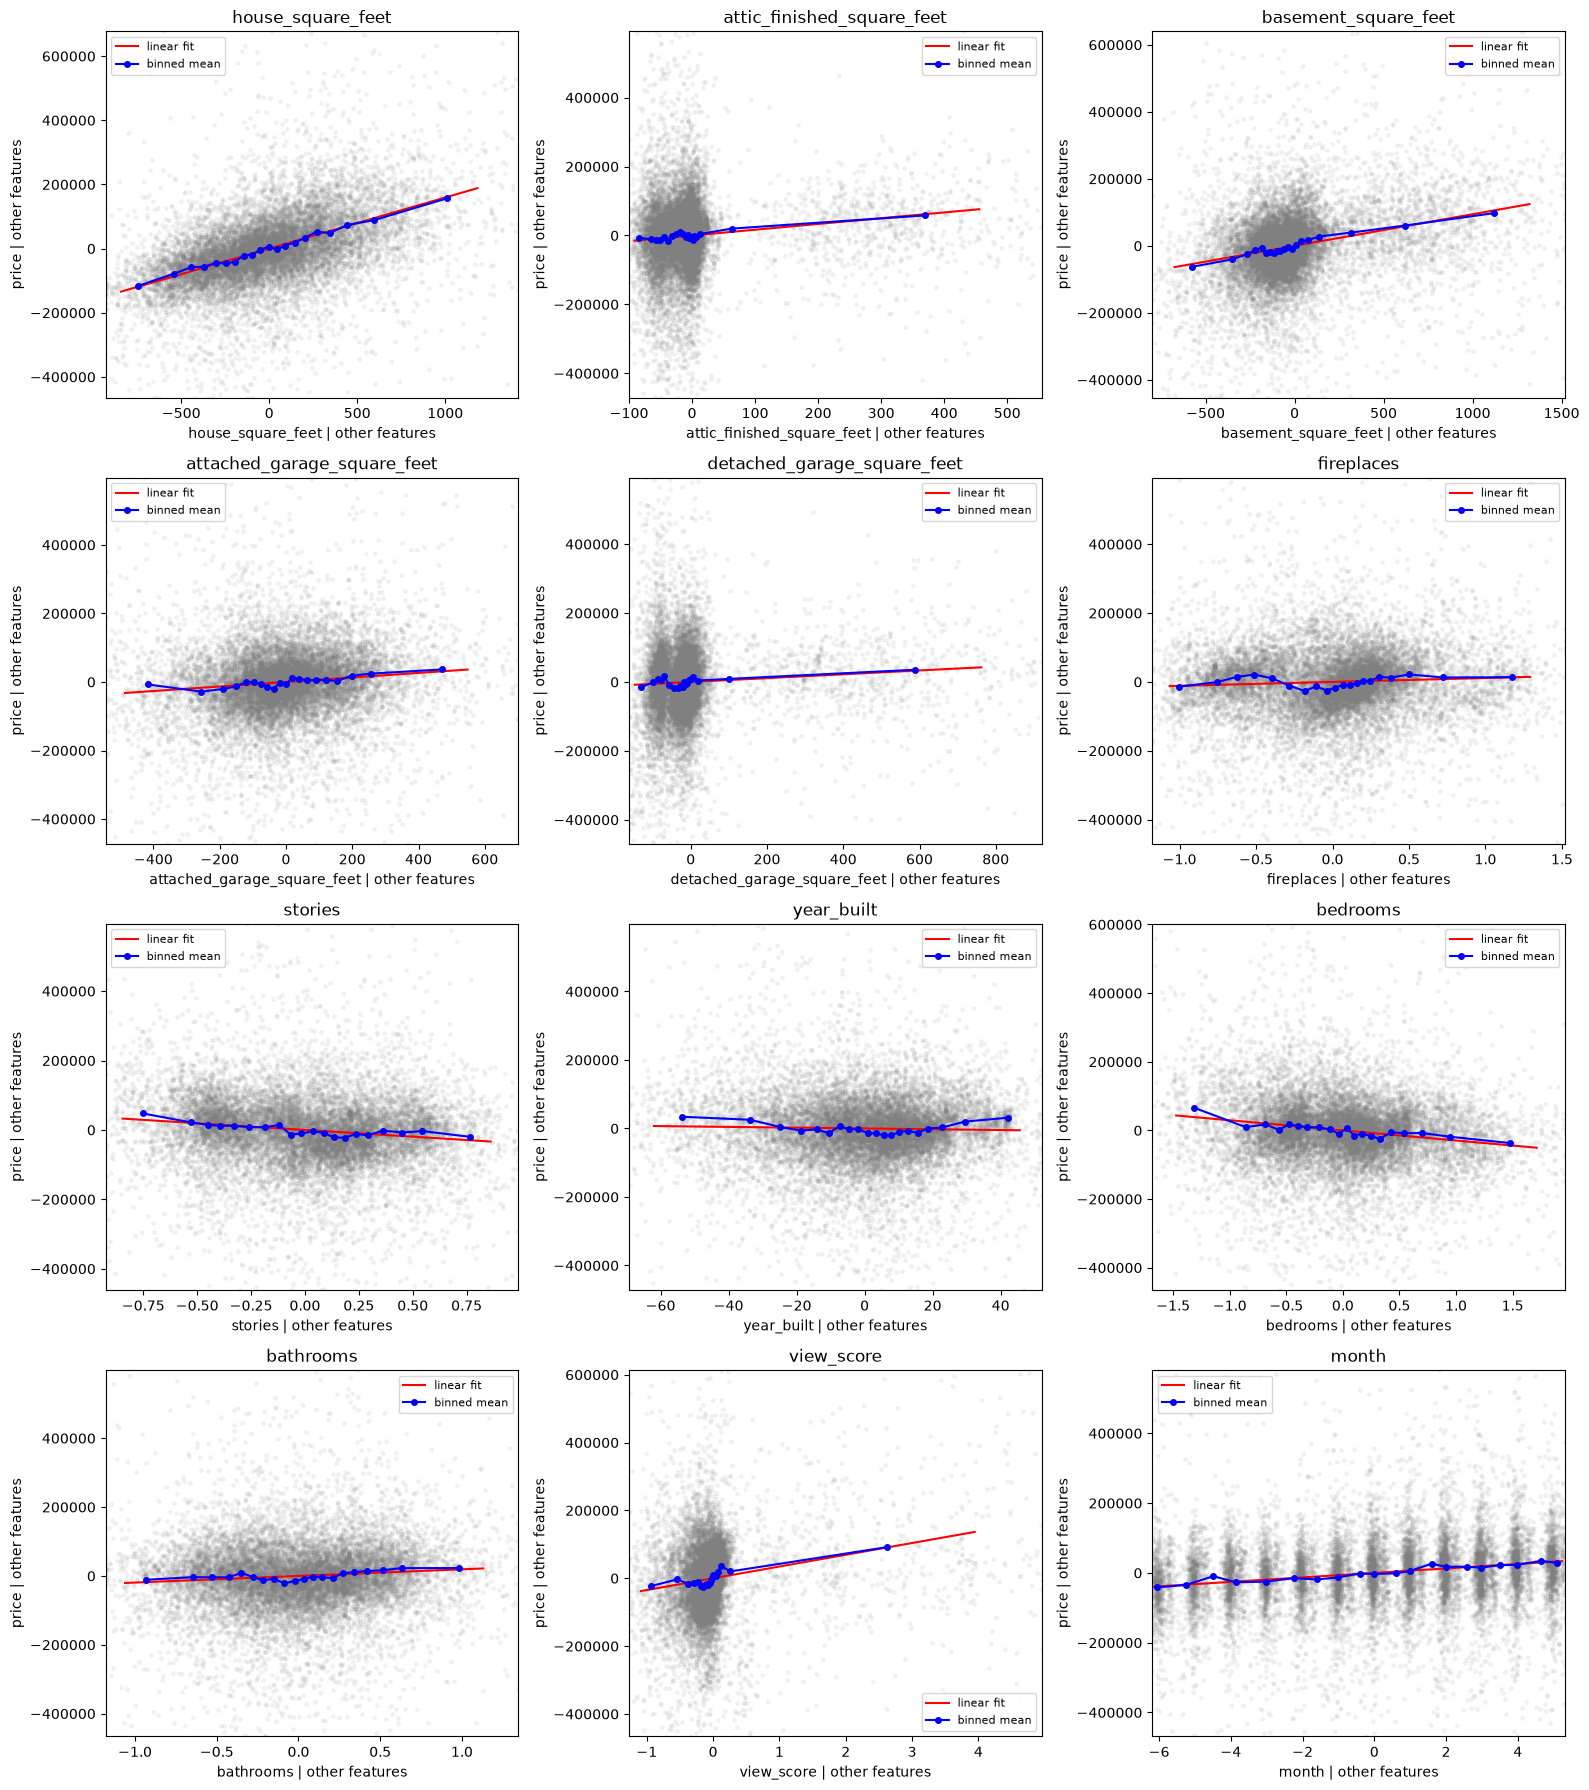

In [ ]:
plot_vars = numeric_vars + ["view_score", "month"]
all_feats = list(X.columns)

fig, axes = plt.subplots(4, 3, figsize=(16, 18))
for ax, var in zip(axes.flat, plot_vars):
    others = [f for f in all_feats if f != var]
    e_y = y_train - LinearRegression().fit(X_train[others], y_train).predict(X_train[others])
    e_x = X_train[var] - LinearRegression().fit(X_train[others], X_train[var]).predict(X_train[others])

    ax.scatter(e_x, e_y, alpha=0.08, s=6, color="gray")

    # linear fit (model's assumption)
    slope = np.polyfit(e_x, e_y, 1)
    xs = np.linspace(e_x.quantile(0.01), e_x.quantile(0.99), 100)
    ax.plot(xs, np.polyval(slope, xs), color="red", label="linear fit")

    # binned means
    bins = pd.qcut(e_x, q=20, duplicates="drop")
    binned = pd.DataFrame({"ex": e_x, "ey": e_y}).groupby(bins, observed=True).mean()
    ax.plot(binned["ex"], binned["ey"], "o-", color="blue", ms=4, label="binned mean")

    # zoom in on the bulk of the data so outliers don't impact plot scaling
    ax.set_xlim(e_x.quantile(0.005), e_x.quantile(0.995))
    ax.set_ylim(e_y.quantile(0.005), e_y.quantile(0.995))
    ax.set_title(var)
    ax.set_xlabel(f"{var} | other features")
    ax.set_ylabel("price | other features")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The red lines and blue binned means are mostly close to linear, but there are a few non-linearities. Specifically, view_score is one of the clearest nonlinearities since nearly all houses have a score of 0, and the binned mean curve is flat for low scores but rises steeply for high scores. This indicates that the premium for a very good view is much larger than that for a limited view. Similarly, attic_finished_square_feet, detached_garage_square_feet, and basement_square_feet are also zero for most houses, meaning that the plots spike at zero and have a sparse tail. Year_build, on the other hand, has a slight U-shape, presenting that the oldest and newest houses sit above the price estimation while mid-aged houses are slightly below it. A quadratic fit would better capture this pattern.

Overall, there are no dramatic non-linearities.

**Q6**

In [ ]:
y_train_t = np.arcsinh(y_train)

X2 = X.copy()

# transformations
X2["log_sqft"] = np.log(sales_df["house_square_feet"])           # diminishing returns to size
X2["log_sqft_sq"] = X2["log_sqft"] ** 2
X2["yb_c"] = sales_df["year_built"] - 1980                       # centered so yb_c and yb_c^2 aren't collinear
X2["yb_c_sq"] = X2["yb_c"] ** 2                                  # U-shape in year built
X2["has_basement"] = (sales_df["basement_square_feet"] > 0).astype(int)
X2["log_basement"] = np.log1p(sales_df["basement_square_feet"])
X2["total_garage"] = sales_df["attached_garage_square_feet"] + sales_df["detached_garage_square_feet"]
X2["has_garage"] = (X2["total_garage"] > 0).astype(int)
X2["has_attic"] = (sales_df["attic_finished_square_feet"] > 0).astype(int)
X2["has_fireplace"] = (sales_df["fireplaces"] > 0).astype(int)
X2["waterfront"] = (df_water.sum(axis=1) > 0).astype(int)
X2["has_view"] = (sales_df["view_score"] > 0).astype(int)

# interactions
X2["logsqft_x_baths"] = X2["log_sqft"] * sales_df["bathrooms"]
X2["logsqft_x_beds"] = X2["log_sqft"] * sales_df["bedrooms"]
X2["logsqft_x_view"] = X2["log_sqft"] * sales_df["view_score"]
X2["logsqft_x_waterfront"] = X2["log_sqft"] * X2["waterfront"]
X2["yb_x_logsqft"] = X2["yb_c"] * X2["log_sqft"]

X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]

complex_reg = LinearRegression().fit(X2_train, y_train_t)
train_hat = np.sinh(complex_reg.predict(X2_train))
test_hat = np.sinh(complex_reg.predict(X2_test))

complex_row = {
    "train RMSE": np.sqrt(mean_squared_error(y_train, train_hat)),
    "test RMSE": np.sqrt(mean_squared_error(y_test, test_hat)),
    "train R2": r2_score(y_train, train_hat),
    "test R2": r2_score(y_test, test_hat),
}
results_q6 = pd.concat([results, pd.DataFrame(complex_row, index=["M6: transforms + interactions"])])
print("Number of features in M6:", X2.shape[1])
display(results_q6.round(3))

from sklearn.model_selection import KFold

def cv_rmse(features_df, log_target):
    errs = []
    for tr, va in KFold(5, shuffle=True, random_state=1).split(features_df):
        t = np.arcsinh(y_train.iloc[tr]) if log_target else y_train.iloc[tr]
        m = LinearRegression().fit(features_df.iloc[tr], t)
        p = m.predict(features_df.iloc[va])
        p = np.sinh(p) if log_target else p
        errs.append(np.sqrt(np.mean((y_train.iloc[va] - p) ** 2)))
    return np.mean(errs)

print("5-fold CV RMSE on training data")
print("M5 (raw price):      ", round(cv_rmse(X_train, False)))
print("M6 (arcsinh target): ", round(cv_rmse(X2_train, True)))

m5_test_pred = LinearRegression().fit(X_train, y_train).predict(X_test)
m6_test_pred = pd.Series(np.sinh(complex_reg.predict(X2_test)), index=y_test.index)
m6_err = (y_test - m6_test_pred).abs().sort_values()
m5_err = (y_test - m5_test_pred).abs().sort_values()
print("\nTest RMSE after dropping each model's 5 largest errors:")
print("M5:", round(np.sqrt((m5_err.iloc[:-5] ** 2).mean())))
print("M6:", round(np.sqrt((m6_err.iloc[:-5] ** 2).mean())))
print("Median absolute test error:  M5:", round(m5_err.median()), "  M6:", round(m6_err.median()))

worst = m6_err.index[-5:][::-1]
display(pd.DataFrame({"Actual Price": y_test[worst], "M6 Prediction": m6_test_pred[worst],
                      "Sq. Feet": X_test.loc[worst, "house_square_feet"]}).round(0))

Number of features in M6: 50


,train RMSE,test RMSE,train R2,test R2
M1: sqft,205050.796,160980.155,0.268,0.389
M2: sqft + beds + baths,202123.361,158617.889,0.288,0.407
M3: all numeric,186606.935,139452.492,0.393,0.542
M4: numeric + waterfront/view/month,167128.436,121088.559,0.513,0.655
M5: everything,165265.820,119882.720,0.524,0.661
M6: transforms + interactions,158335.212,127472.740,0.563,0.617


5-fold CV RMSE on training data
M5 (raw price):       165102
M6 (arcsinh target):  157569

Test RMSE after dropping each model's 5 largest errors:
M5: 112179
M6: 108925
Median absolute test error:  M5: 51320   M6: 46531


,Actual Price,M6 Prediction,Sq. Feet
7060,2273000,4888612.0,7725
5531,1525000,3066438.0,6355
11700,2038200,549891.0,1031
9439,1000000,2283199.0,6963
11112,1935500,659127.0,592


The M6 model fits the training data better, with a train RMSE about $158k and R² 0.563, versus about $165k and 0.524 for M5. It's 5-fold cross validation on the training data was also better, with ~$158k versus $165k for M5. However, M6 did worse on the held-out test set with a test RMSE of ~$127k and R² 0.617, versus ~$120k and 0.661 for M5.

Hence, M6 is the better model for typpical houses since it's median absolute test error is lower than M5's. It's drawbacks come when evaluating extreme houses. For instance, a 7,725 sq ft house that sold for about $2.3M was predicted at about $4.9M, and a 6,355 sq ft house was predicted at roughly double its sale price. The fact that the model is weak at the extremes, and that the squared and interaction terms in size extrapolates signficiantly for very large houses, indicates that the model is slightly overfitted.

**Q7**

Summary:
In Q1-Q3, we cleaned the data by merging duplicate categories and dropping missing rows. We found that prices were right-skewed, so we used an arcsinh transform for the log-scale analysis. In Q4, the test R^2 increased from 0.389 to 0.661 while the test RMSE decreased from from ~161k to ~120. Most of the gain came from adding waterfront, view, and month while heating, exterior, and roof type added very little. In Q5, the partial correlation plots showed mostly linear relationships, with slight non-linearities in year built and view scores. In Q6, the M6 model improved both training RMSE and R^2 and cross-validated RMSE on the training data. However, its test RMSE and R^2 were worse than those of M5 because of over-predicting vary large houses.

Model under/overfitting & selection:
Overall, training error always improves as a model gets more flexible, so it's not a reliable factor in choosing a model. For instance, M6 has the lowest training error but not the lowest test error. Additionally, test RMSE can be heavily influenced by a few extreme observation (ie. a few very large houses), so a single train/test split is noisy when choosing models. Hence, cross-validation, medians, and looking at the worst predictions are necessary for choosing a model.

**Q8**

In [ ]:
from sklearn.linear_model import LassoCV, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Lasso penalty depends on feature scale, so we need to standardize first.
# penalty strength chosen by 5-fold cross-validation on only the training data.
lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, max_iter=50000, random_state=42),
)
lasso_cv.fit(X2_train, y_train_t)
cv_model = lasso_cv[-1]

# two choices for alpha:
#  a) alpha with the lowest cross-validated error
#  b) largest alpha whose CV error is within one standard error of the minimum
mean_mse = cv_model.mse_path_.mean(axis=1)
se_mse = cv_model.mse_path_.std(axis=1) / np.sqrt(cv_model.mse_path_.shape[1])
best = np.argmin(mean_mse)
alpha_1se = max(a for a, m in zip(cv_model.alphas_, mean_mse) if m <= mean_mse[best] + se_mse[best])
print("alpha (min CV error):", cv_model.alpha_, "  alpha (1-SE rule):", alpha_1se)

lasso_1se = make_pipeline(StandardScaler(), Lasso(alpha=alpha_1se, max_iter=50000))
lasso_1se.fit(X2_train, y_train_t)

def metrics(model):
    tr, te = np.sinh(model.predict(X2_train)), np.sinh(model.predict(X2_test))
    return {"train RMSE": np.sqrt(mean_squared_error(y_train, tr)),
            "test RMSE": np.sqrt(mean_squared_error(y_test, te)),
            "train R2": r2_score(y_train, tr), "test R2": r2_score(y_test, te)}

for label, mdl in [("min-CV alpha", lasso_cv), ("1-SE alpha", lasso_1se)]:
    c = pd.Series(mdl[-1].coef_, index=X2.columns)
    print(f"\n{label}: kept {(c != 0).sum()} of {len(c)} features")
    if label == "1-SE alpha":
        print(c[c != 0].sort_values(key=abs, ascending=False).round(4).to_string())
        print("\nDropped:", list(c[c == 0].index))

results_q8 = pd.concat([results_q6, pd.DataFrame(
    [metrics(lasso_cv), metrics(lasso_1se)],
    index=["M7a: Lasso (min-CV alpha)", "M7b: Lasso (1-SE alpha)"])])
display(results_q8.round(3))

alpha (min CV error): 0.00024320868080376004   alpha (1-SE rule): 0.009156650708808358

min-CV alpha: kept 42 of 50 features

1-SE alpha: kept 23 of 50 features
house_square_feet              0.1349
wf_WF Salt                     0.0631
log_sqft_sq                    0.0479
basement_square_feet           0.0444
wf_WF Lake                     0.0380
month                          0.0358
total_garage                   0.0320
view_score                     0.0313
bathrooms                      0.0261
log_basement                   0.0230
hvac_Heat Pump                 0.0195
ext_Frame Vinyl               -0.0174
fireplaces                     0.0144
attic_finished_square_feet     0.0133
has_view                       0.0118
hvac_Warm and Cool Air Zone    0.0114
year_built                     0.0088
stories                       -0.0075
waterfront                     0.0066
bedrooms                      -0.0053
attached_garage_square_feet    0.0050
roof_Composition Shingle      -0.0024
ext

,train RMSE,test RMSE,train R2,test R2
M1: sqft,205050.796,160980.155,0.268,0.389
M2: sqft + beds + baths,202123.361,158617.889,0.288,0.407
M3: all numeric,186606.935,139452.492,0.393,0.542
M4: numeric + waterfront/view/month,167128.436,121088.559,0.513,0.655
M5: everything,165265.820,119882.720,0.524,0.661
M6: transforms + interactions,158335.212,127472.740,0.563,0.617
M7a: Lasso (min-CV alpha),159156.630,129413.345,0.559,0.605
M7b: Lasso (1-SE alpha),166070.210,127545.643,0.520,0.617


For the lowest CV error alpha, the Lasso kept 42 of 50 features since it has a small penalty. The test RMSE is ~$129k and the test R² is 0.605, which is not improved from the unregularized M6.

For the one standard error alpha, the Lasso kept 23 of 50 features. It dropped all five of the interaction terms. In terms of performance, the train had an RMSE of ~$166k and R² of 0.520, while the test had an RMSE of ~$128k and R² of 0.617. This matches the test performance of the full M6 and is better than the result from the lowest CV error Lasso despite using less than half of the features. It also has a much smaller train/test gap in RMSE than M6 and does not beat the simple M5 on the test set (RMSE about $120k, R² 0.661). Consistent with Q7, it indicates that the test results are dominated by a few very large houses that the log-scale models over-predict.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID: 94f601b08a5b5736a3c4c1dec019e48af678cb5a
- **AI tool and model used:** Claude Sonnet 5.5, made by Anthropic

### *Prompts used

1. I have already completed phase one of the assignment, answering each question. I have attached the Phase 1 code and the questions I was supposed to answer in this message. Review the code and give me suggestions on how to improve it and correct any mistakes.
2. I uploaded the template of all the things I need to include in the Phase 2 template (to organize the response better).

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]
1. Q1: Add .copy() after dropping/filtering rows and remove the duplicated imports to avoid SettingWithCopyWarning.
2. Q1: Add data-validity checks before modeling: drop exact duplicate rows, inspect both tails of sale_price and house_square_feet, filter implausible year_built values (< 1800), and print the sale_date range.
3. Q1 (optional): Remove the top 1% of sale prices as outliers.
4. Q2: Replace drop_first=True with an explicit reference level (the most common category) for every categorical variable, because drop_first drops the alphabetically first level (not necessarily "None" for waterfront).
5. Q2: Replace the linear numeric "month" feature with month dummies, and add a sale_trend (months since first sale) when sales span more than one year.
6. Q3: Stratify the 80/20 split on price deciles and print train/test price summaries to confirm the two sets look alike.
7. Q4: Add a predict-the-training-mean baseline, 5-fold CV RMSE on the training data, and a train-test gap column; pick the best model by CV RMSE rather than by test performance.
8. Q5: Quantify non-linearity for each partial plot (1 - R^2 of a linear fit to the binned means) and hide unused subplot axes.
9. Q6: Remove perfectly collinear features (total_garage = attached + detached; waterfront = sum of waterfront dummies) from the feature matrix, keep them only as temporary variables, and add a matrix-rank check.
10. Q6: Center log(square feet) before squaring it and before building interactions.
11. Q6: Correct retransformation bias from the arcsinh target (smearing correction), compare it against plain sinh using CV RMSE, and keep a USE_SMEARING switch.
12. Q7: Add a summary table with number of features and test/train RMSE ratio, plus a bar chart of train vs test RMSE, to support the overfitting/underfitting discussion.
13. Q8: Label the Lasso models M8a/M8b (not M7), print the selected features at both alpha values, plot the CV curve with the min-CV and 1-SE alphas marked, and apply the same retransformation correction.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
|Remove perfectly collinear columns from the feature matrix. total_garage (attached + detached garage) and waterfront (sum of the waterfront dummies) are exact linear combinations of existing columns, so keep them only as temporary variables and add a matrix-rank check. | Accept | We decided to accept this suggestion because total_garage and waterfront were exact linear combinations of other columns, so the design matrix was rank-deficient. This was verified by printing np.linalg.matrix_rank(X2_train) and confirming it equals the number of columns, and by checking that M6 train/test RMSE and R^2 did not get worse. |
| Fix the categorical encoding. Replace drop_first=True with an explicit reference level (the most common category) for each categorical variable, and replace the numeric "month" column with month dummies, since month 12 is not "12 times" month 1. | Accept | We decided to accept this suggestio because drop_first drops the alphabetically first level, which is not necessarily the intended baseline, and a linear month number imposes a false ordering on seasonality. This was verified by printing the reference level for each categorical (the most common category, "None" for waterfront) and checking the new month dummy columns in X.shape and X.head()|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.
%pip install numpy pandas matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


(16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000


hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric                      2
Floor Wall Furnace            1
Name: count, dtype: int64 

exterior
Frame Siding              14577
Frame Vinyl                1724
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5
Unfinished Cottage            4
Pine Finished Cabin           4
Cedar A-Frame                 2
Cedar Unfinished Cabin        2
Pine Unfinished Cabin         2
NaN                           1
Pine A-Frame                  1
Name: count, dtype: int64 

interior
Drywall     16777
Paneling       30
NaN      

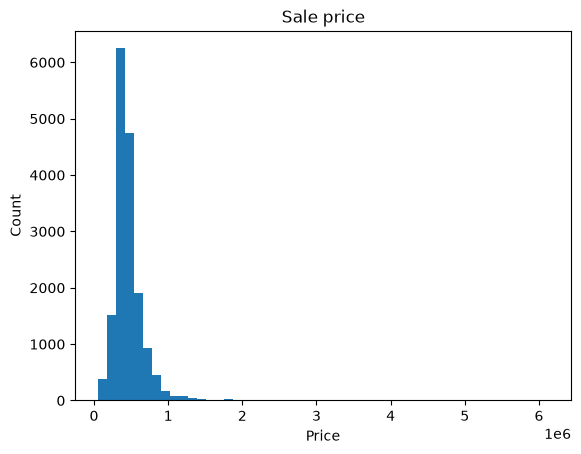

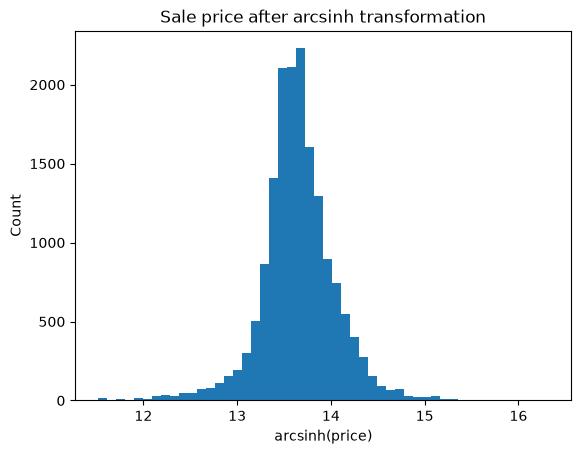

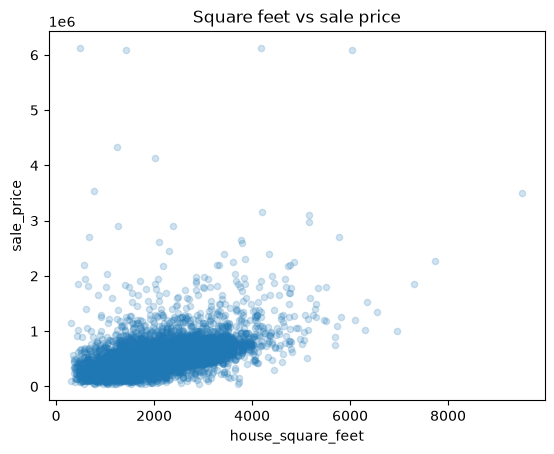

sale_price                     1.00
house_square_feet              0.53
bathrooms                      0.42
fireplaces                     0.35
attached_garage_square_feet    0.31
basement_square_feet           0.27
year_built                     0.23
bedrooms                       0.21
stories                        0.17
detached_garage_square_feet    0.05
attic_finished_square_feet     0.02
Name: sale_price, dtype: float64
view_quality
None            410000.0
View Lim -      575000.0
View Lim        600000.0
View Avg        679500.0
View Lim +      699000.0
View Avg +      800000.0
View Good       800000.0
View Good +     856250.0
View V-Good    1142000.0
Name: sale_price, dtype: float64
Sales span more than one year: False


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Q1
sales_df = pd.read_csv("pierce_county_house_sales.csv")

print(sales_df.shape)
display(sales_df.head())
sales_df.info()
print(sales_df.isna().sum())
display(sales_df.describe())

# Look at categorical columns
for col in ["hvac_description", "exterior", "interior", "roof_cover",
            "waterfront_type", "view_quality", "utility_sewer"]:
    print(sales_df[col].value_counts(dropna=False), "\n")

# Standardize names
sales_df["waterfront_type"] = sales_df["waterfront_type"].fillna("None")
sales_df["view_quality"] = sales_df["view_quality"].fillna("None")
sales_df["hvac_description"] = sales_df["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# Drop missing rows (.copy() avoids SettingWithCopyWarning later)
sales_df = sales_df.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"]).copy()
sales_df["sale_date"] = pd.to_datetime(sales_df["sale_date"])

# Data-validity checks
n_before = len(sales_df)
sales_df = sales_df.drop_duplicates()
print("Duplicate rows dropped:", n_before - len(sales_df))
print("Sale dates:", sales_df["sale_date"].min(), "to", sales_df["sale_date"].max())

print(sales_df.sort_values("sale_price").head(10))
print(sales_df.sort_values("sale_price").tail(10))
print(sales_df.sort_values("house_square_feet").head(10))
print(sales_df.sort_values("house_square_feet").tail(10))
print(sales_df["year_built"].describe())
print(sales_df["bedrooms"].value_counts())
print(sales_df["bathrooms"].value_counts())
print(sales_df["stories"].value_counts())

# Drop rows that don't make sense
sales_df = sales_df.query(
    "sale_price >= 50000 and house_square_feet >= 300 and bedrooms <= 10 "
    "and stories > 0 and bathrooms > 0 and year_built >= 1800"
).copy()
print(sales_df.shape)

# Histogram of sale price
sales_df["sale_price"].hist(bins=50, grid=False)
plt.title("Sale price")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# Transformed because of long right tail
sales_df["price_arcsinh"] = np.arcsinh(sales_df["sale_price"])
sales_df["price_arcsinh"].hist(bins=50, grid=False)
plt.title("Sale price after arcsinh transformation")
plt.xlabel("arcsinh(price)")
plt.ylabel("Count")
plt.show()

# Square feet vs price
sales_df.plot.scatter(x="house_square_feet", y="sale_price", alpha=0.2)
plt.title("Square feet vs sale price")
plt.show()

# Correlations with price
numeric_cols = ["sale_price", "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
                "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
                "stories", "year_built", "bedrooms", "bathrooms"]
print(sales_df[numeric_cols].corr()["sale_price"].sort_values(ascending=False).round(2))

# Median price
print(sales_df.groupby("view_quality")["sale_price"].median().sort_values())

# Time features for later questions
sales_df["month"] = sales_df["sale_date"].dt.month
multi_year = sales_df["sale_date"].dt.year.nunique() > 1
sales_df["sale_trend"] = ((sales_df["sale_date"].dt.year - sales_df["sale_date"].dt.year.min()) * 12
                          + sales_df["month"])  # months since start of first year (market trend)
time_vars = ["sale_trend"] if multi_year else []
print("Sales span more than one year:", multi_year)

In [ ]:
# Q2
# Assign numbers to view_quality
view_scores = {"None": 0, "View Lim -": 1, "View Lim": 2, "View Lim +": 3, "View Avg": 4,
               "View Avg +": 5, "View Good": 6, "View Good +": 7, "View V-Good": 8}
sales_df["view_score"] = sales_df["view_quality"].map(view_scores)
assert sales_df["view_score"].notna().all(), "Unmapped view_quality value"

# Make interior and sewer a 0/1 variable because both are mostly the same value
sales_df["paneling"] = (sales_df["interior"] == "Paneling").astype(int)
sales_df["sewer_installed"] = (sales_df["utility_sewer"] == "SEWER/SEPTIC INSTALLED").astype(int)

# Combine small categories
sales_df["hvac"] = sales_df["hvac_description"].replace("Electric", "Electric Baseboard")
sales_df["ext"] = sales_df["exterior"]
small_exteriors = sales_df["ext"].value_counts()[sales_df["ext"].value_counts() < 50].index
sales_df["ext"] = sales_df["ext"].replace(list(small_exteriors), "Other")
print(sales_df["hvac"].value_counts(), "\n")
print(sales_df["ext"].value_counts(), "\n")

# One-hot encode. The reference level is the MOST COMMON category
# (drop_first would drop the alphabetically first one instead).
def dummies(series, prefix):
    ref = series.value_counts().idxmax()
    d = pd.get_dummies(series, prefix=prefix, dtype=int)
    return d.drop(columns=f"{prefix}_{ref}")

for col in ["waterfront_type", "hvac", "ext", "roof_cover", "month"]:
    print(f"Reference level for {col}:", sales_df[col].value_counts().idxmax())

df_water = dummies(sales_df["waterfront_type"], "wf")
df_hvac = dummies(sales_df["hvac"], "hvac")
df_ext = dummies(sales_df["ext"], "ext")
df_roof = dummies(sales_df["roof_cover"], "roof")
df_month = dummies(sales_df["month"], "month")   # seasonality as categories, not a linear number

numeric_vars = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
                "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
                "stories", "year_built", "bedrooms", "bathrooms"]
other_vars = ["view_score", "paneling", "sewer_installed"] + time_vars

X = pd.concat([sales_df[numeric_vars + other_vars], df_water, df_hvac, df_ext, df_roof, df_month], axis=1)
y = sales_df["sale_price"]

print("X shape:", X.shape)
display(X.head())

hvac
Forced Air                10309
Electric Baseboard         2641
Heat Pump                  2066
Warm and Cool Air Zone     1261
Floor/Wall Furnace          171
Hot Water Baseboard         146
No Heat                      64
Name: count, dtype: int64 

ext
Frame Siding            14466
Frame Vinyl              1711
Masonry Common Brick      208
Frame Stucco              156
Other                     117
Name: count, dtype: int64 

Reference level for waterfront_type: None
Reference level for hvac: Forced Air
Reference level for ext: Frame Siding
Reference level for roof_cover: Composition Shingle
Reference level for month: 10
X shape: (16658, 43)


,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms,...,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_11,month_12
0,2157,0,0,528,0,0,2,1993,3,3,...,0,0,0,0,0,0,0,0,0,0
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,0,0,0
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,0,0,0
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,0,0,0
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Q3: 80/20 split, stratified on price deciles so both sets have similar price distributions
price_bins = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=price_bins
)
print("Train:", X_train.shape, " Test:", X_test.shape)
display(pd.concat([y_train.describe(), y_test.describe()], axis=1, keys=["train", "test"]).round(0))

Train: (13326, 43)  Test: (3332, 43)


,train,test
count,13326.0,3332.0
mean,461522.0,462334.0
std,234464.0,228677.0
min,50000.0,66404.0
25%,348750.0,349950.0
50%,417000.0,417000.0
75%,523000.0,524301.0
max,6130000.0,4334100.0


In [ ]:
# Q4
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

def row(tr_hat, te_hat):
    return {"train RMSE": rmse(y_train, tr_hat), "test RMSE": rmse(y_test, te_hat),
            "train R2": r2_score(y_train, tr_hat), "test R2": r2_score(y_test, te_hat)}

def cv_rmse(features_df, log_target=False, smear=False):
    """5-fold CV RMSE (in dollars) using only the training data."""
    errs = []
    for tr, va in KFold(5, shuffle=True, random_state=1).split(features_df):
        t = np.arcsinh(y_train.iloc[tr]) if log_target else y_train.iloc[tr]
        m = LinearRegression().fit(features_df.iloc[tr], t)
        p = m.predict(features_df.iloc[va])
        if log_target:
            if smear:
                r = t - m.predict(features_df.iloc[tr])
                p = np.sinh(p) * np.cosh(r).mean() + np.cosh(p) * np.sinh(r).mean()
            else:
                p = np.sinh(p)
        errs.append(rmse(y_train.iloc[va], p))
    return np.mean(errs)

water_vars = list(df_water.columns)
month_vars = list(df_month.columns)

model_features = {
    "M1: sqft": ["house_square_feet"],
    "M2: sqft + beds + baths": ["house_square_feet", "bedrooms", "bathrooms"],
    "M3: all numeric": numeric_vars,
    "M4: numeric + waterfront/view/time": numeric_vars + water_vars + ["view_score"] + time_vars + month_vars,
    "M5: everything": list(X.columns),
}

# Baseline: always predict the training mean
base_tr = np.full(len(y_train), y_train.mean())
base_te = np.full(len(y_test), y_train.mean())
rows = {"M0: predict train mean": {**row(base_tr, base_te), "CV RMSE": np.nan}}

for name, features in model_features.items():
    reg = LinearRegression().fit(X_train[features], y_train)
    rows[name] = {**row(reg.predict(X_train[features]), reg.predict(X_test[features])),
                  "CV RMSE": cv_rmse(X_train[features])}

results = pd.DataFrame(rows).T
results["RMSE gap (test-train)"] = results["test RMSE"] - results["train RMSE"]
display(results.round(3))
print("Best model by CV RMSE (training data only):", results["CV RMSE"].idxmin())

,train RMSE,test RMSE,train R2,test R2,CV RMSE,RMSE gap (test-train)
M0: predict train mean,234454.953,228643.696,0.000,-0.000,NaN,-5811.257
M1: sqft,198257.974,192512.926,0.285,0.291,196672.618,-5745.049
M2: sqft + beds + baths,195607.099,188959.616,0.304,0.317,194031.853,-6647.483
M3: all numeric,179472.264,173151.093,0.414,0.426,178183.645,-6321.171
M4: numeric + waterfront/view/time,159460.886,156396.711,0.537,0.532,158847.815,-3064.175
M5: everything,157491.131,155682.225,0.549,0.536,157579.317,-1808.907


Best model by CV RMSE (training data only): M5: everything


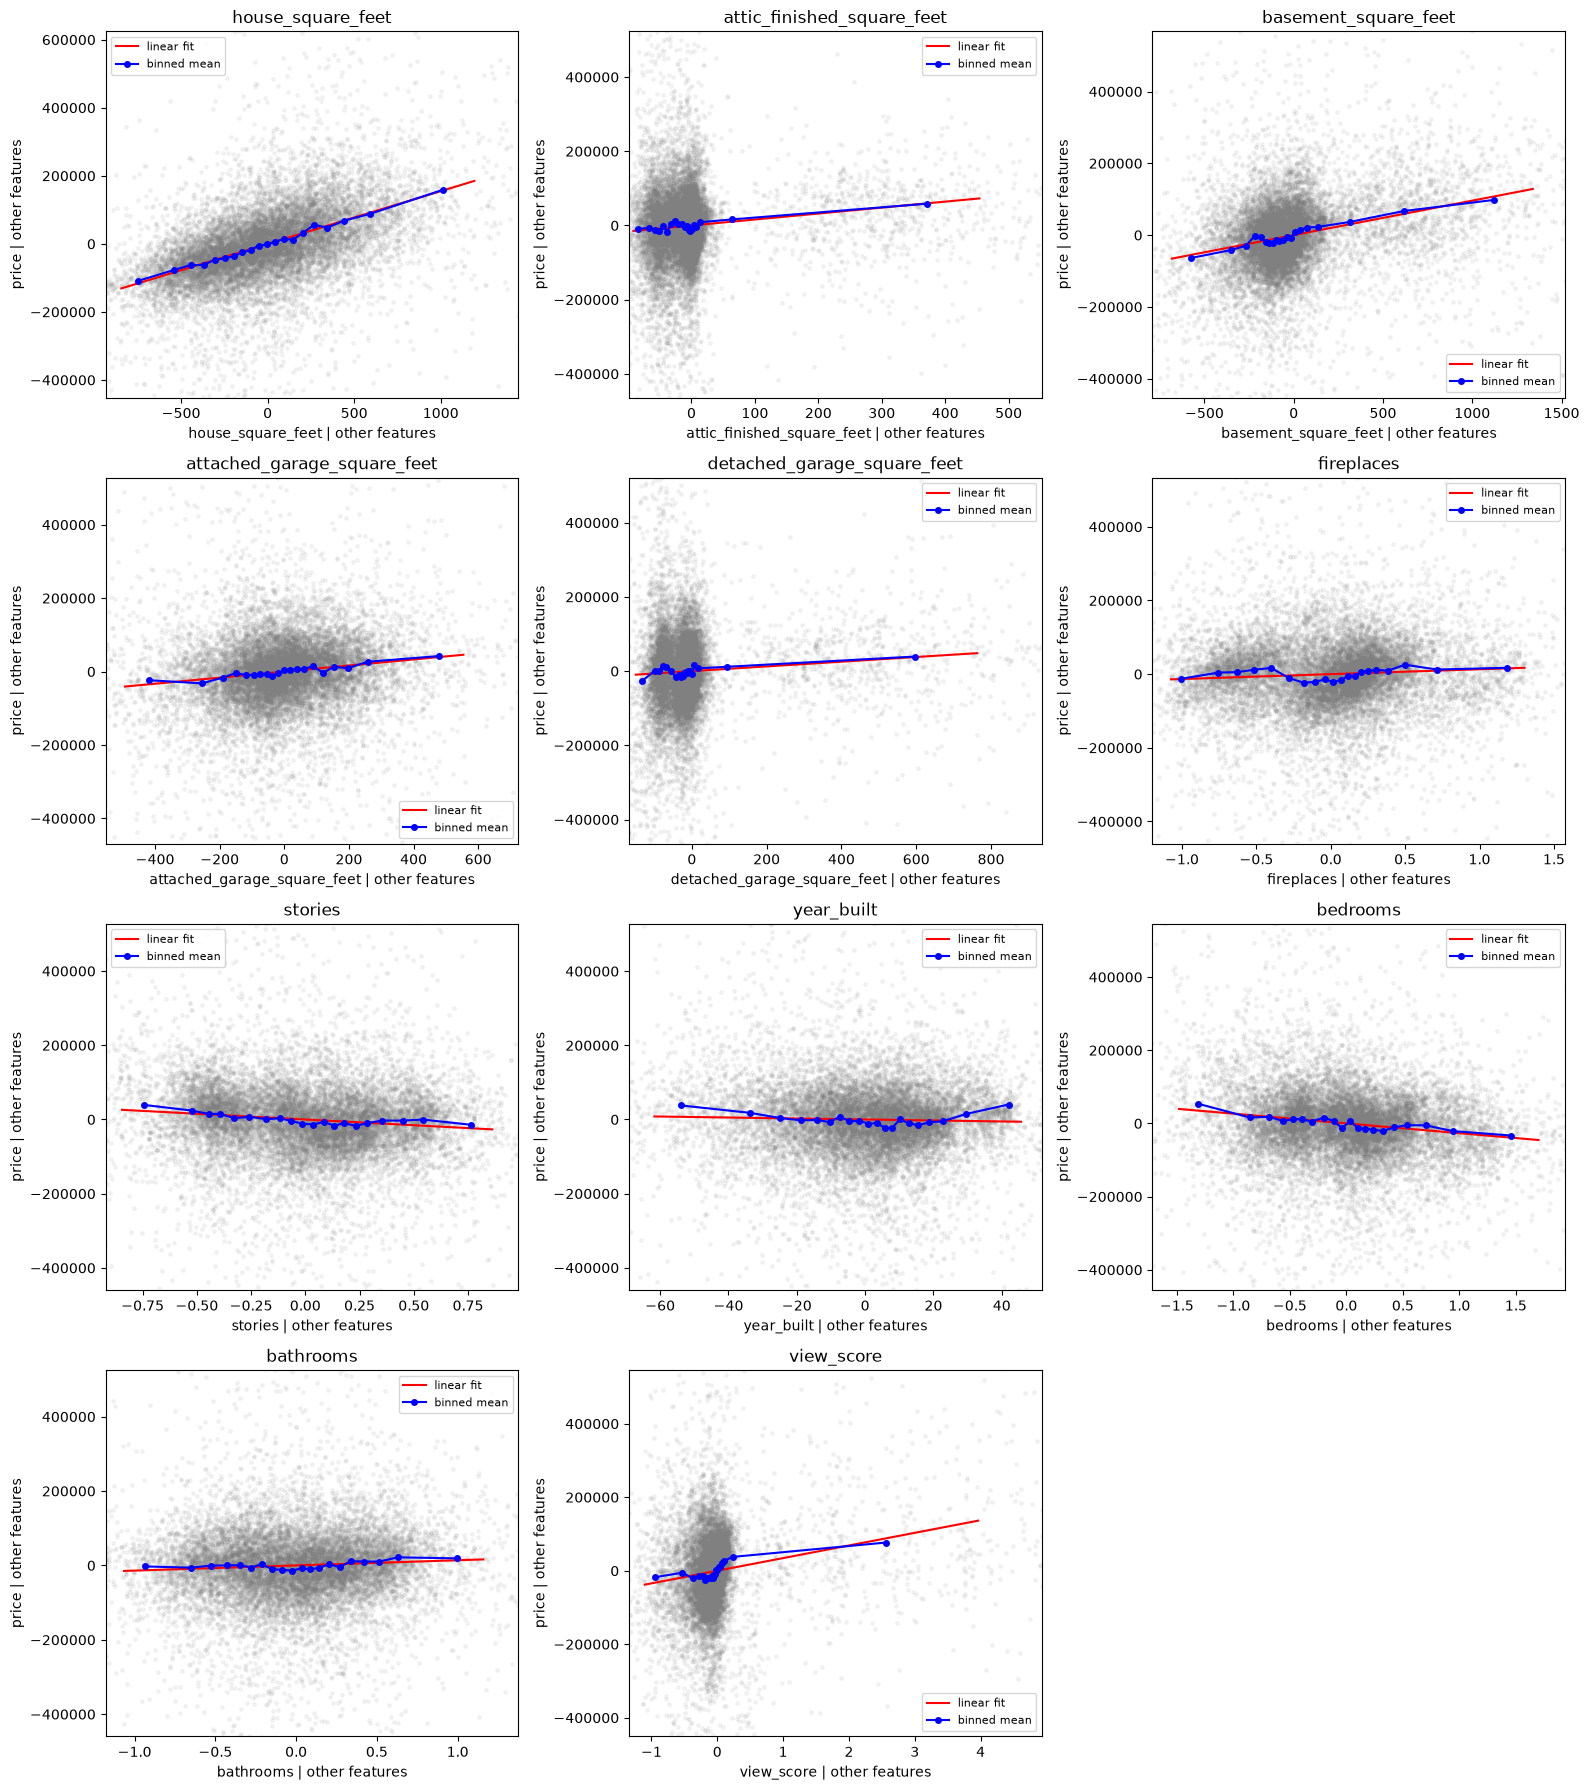

Departure from linearity of binned means (1 - R^2), higher = more non-linear:
year_built                     0.958
fireplaces                     0.867
bathrooms                      0.640
detached_garage_square_feet    0.511
stories                        0.389
view_score                     0.326
attic_finished_square_feet     0.232
bedrooms                       0.232
attached_garage_square_feet    0.140
basement_square_feet           0.068
house_square_feet              0.008
dtype: float64


In [ ]:
# Q5: partial regression (added-variable) plots
plot_vars = numeric_vars + ["view_score"] + time_vars
all_feats = list(X.columns)

fig, axes = plt.subplots(4, 3, figsize=(16, 18))
nonlin = {}
for ax, var in zip(axes.flat, plot_vars):
    others = [f for f in all_feats if f != var]
    e_y = y_train - LinearRegression().fit(X_train[others], y_train).predict(X_train[others])
    e_x = X_train[var] - LinearRegression().fit(X_train[others], X_train[var]).predict(X_train[others])

    ax.scatter(e_x, e_y, alpha=0.08, s=6, color="gray")

    # linear fit (the model's assumption)
    slope = np.polyfit(e_x, e_y, 1)
    xs = np.linspace(e_x.quantile(0.01), e_x.quantile(0.99), 100)
    ax.plot(xs, np.polyval(slope, xs), color="red", label="linear fit")

    # binned means
    bins = pd.qcut(e_x, q=20, duplicates="drop")
    binned = pd.DataFrame({"ex": e_x, "ey": e_y}).groupby(bins, observed=True).mean()
    ax.plot(binned["ex"], binned["ey"], "o-", color="blue", ms=4, label="binned mean")

    # 0 = binned means lie on a straight line; larger = more curvature
    nonlin[var] = 1 - np.corrcoef(binned["ex"], binned["ey"])[0, 1] ** 2

    # zoom in on the bulk of the data so outliers don't dominate the scale
    ax.set_xlim(e_x.quantile(0.005), e_x.quantile(0.995))
    ax.set_ylim(e_y.quantile(0.005), e_y.quantile(0.995))
    ax.set_title(var)
    ax.set_xlabel(f"{var} | other features")
    ax.set_ylabel("price | other features")
    ax.legend(fontsize=8)

for ax in axes.flat[len(plot_vars):]:   # hide unused panels
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Departure from linearity of binned means (1 - R^2), higher = more non-linear:")
print(pd.Series(nonlin).sort_values(ascending=False).round(3))

In [ ]:
# Q6
USE_SMEARING = True   # set to False if the CV RMSE column below shows no gain from M6b

y_train_t = np.arcsinh(y_train)
X2 = X.copy()

# transformations
log_sqft = np.log(sales_df["house_square_feet"])
lsq_mean = log_sqft.loc[X_train.index].mean()               # center using training data only
X2["log_sqft_c"] = log_sqft - lsq_mean                      # diminishing returns to size
X2["log_sqft_c_sq"] = X2["log_sqft_c"] ** 2
X2["yb_c"] = sales_df["year_built"] - 1980                  # centered so yb_c and yb_c^2 aren't collinear
X2["yb_c_sq"] = X2["yb_c"] ** 2                             # U-shape in year built
X2["has_basement"] = (sales_df["basement_square_feet"] > 0).astype(int)
X2["log_basement"] = np.log1p(sales_df["basement_square_feet"])

# Temporary variables only: total_garage = attached + detached and waterfront = sum of the
# waterfront dummies, so adding them as columns would make the design matrix rank-deficient.
total_garage = sales_df["attached_garage_square_feet"] + sales_df["detached_garage_square_feet"]
waterfront = (sales_df["waterfront_type"] != "None").astype(int)

X2["has_garage"] = (total_garage > 0).astype(int)
X2["has_attic"] = (sales_df["attic_finished_square_feet"] > 0).astype(int)
X2["has_fireplace"] = (sales_df["fireplaces"] > 0).astype(int)
X2["has_view"] = (sales_df["view_score"] > 0).astype(int)

# interactions
X2["logsqft_x_baths"] = X2["log_sqft_c"] * sales_df["bathrooms"]
X2["logsqft_x_beds"] = X2["log_sqft_c"] * sales_df["bedrooms"]
X2["logsqft_x_view"] = X2["log_sqft_c"] * sales_df["view_score"]
X2["logsqft_x_waterfront"] = X2["log_sqft_c"] * waterfront
X2["yb_x_logsqft"] = X2["yb_c"] * X2["log_sqft_c"]

X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]
print("Feature matrix rank:", np.linalg.matrix_rank(X2_train.values), "of", X2_train.shape[1], "columns")

def make_to_price(resid, smear):
    """arcsinh scale -> dollars. Smearing corrects for predicting the median instead of the mean."""
    if not smear:
        return np.sinh
    A, B = np.cosh(resid).mean(), np.sinh(resid).mean()    # E[sinh(p + e)] = sinh(p)*E[cosh e] + cosh(p)*E[sinh e]
    return lambda p: np.sinh(p) * A + np.cosh(p) * B

complex_reg = LinearRegression().fit(X2_train, y_train_t)
resid6 = y_train_t - complex_reg.predict(X2_train)
plain, smeared = make_to_price(resid6, False), make_to_price(resid6, True)
to_price6 = smeared if USE_SMEARING else plain

p_tr, p_te = complex_reg.predict(X2_train), complex_reg.predict(X2_test)
m6_rows = pd.DataFrame(
    [{**row(plain(p_tr), plain(p_te)), "CV RMSE": cv_rmse(X2_train, True)},
     {**row(smeared(p_tr), smeared(p_te)), "CV RMSE": cv_rmse(X2_train, True, smear=True)}],
    index=["M6: transforms + interactions", "M6b: + retransformation correction"])

results_q6 = pd.concat([results, m6_rows])
results_q6["RMSE gap (test-train)"] = results_q6["test RMSE"] - results_q6["train RMSE"]
print("Number of features in M6:", X2.shape[1])
display(results_q6.round(3))

# Error analysis (M5 vs M6 using the chosen retransformation)
m5_test_pred = LinearRegression().fit(X_train, y_train).predict(X_test)
m6_test_pred = pd.Series(to_price6(complex_reg.predict(X2_test)), index=y_test.index)
m6_err = (y_test - m6_test_pred).abs().sort_values()
m5_err = (y_test - m5_test_pred).abs().sort_values()
print("\nTest RMSE after dropping each model's 5 largest errors:")
print("M5:", round(np.sqrt((m5_err.iloc[:-5] ** 2).mean())))
print("M6:", round(np.sqrt((m6_err.iloc[:-5] ** 2).mean())))
print("Median absolute test error:  M5:", round(m5_err.median()), "  M6:", round(m6_err.median()))

worst = m6_err.index[-5:][::-1]
display(pd.DataFrame({"Actual Price": y_test[worst], "M6 Prediction": m6_test_pred[worst],
                      "Sq. Feet": X_test.loc[worst, "house_square_feet"]}).round(0))

Feature matrix rank: 58 of 58 columns
Number of features in M6: 58


,train RMSE,test RMSE,train R2,test R2,CV RMSE,RMSE gap (test-train)
M0: predict train mean,234454.953,228643.696,0.000,-0.000,NaN,-5811.257
M1: sqft,198257.974,192512.926,0.285,0.291,196672.618,-5745.049
M2: sqft + beds + baths,195607.099,188959.616,0.304,0.317,194031.853,-6647.483
M3: all numeric,179472.264,173151.093,0.414,0.426,178183.645,-6321.171
M4: numeric + waterfront/view/time,159460.886,156396.711,0.537,0.532,158847.815,-3064.175
M5: everything,157491.131,155682.225,0.549,0.536,157579.317,-1808.907
M6: transforms + interactions,152349.940,153943.776,0.578,0.547,154447.121,1593.836
M6b: + retransformation correction,151215.334,153078.626,0.584,0.552,153666.598,1863.291



Test RMSE after dropping each model's 5 largest errors:
M5: 122681
M6: 118018
Median absolute test error:  M5: 54202   M6: 48728


,Actual Price,M6 Prediction,Sq. Feet
5390,4334100,319281.0,1240
13593,2900000,454032.0,2386
13594,2900000,502601.0,1260
5531,1525000,2979191.0,6355
6776,1700000,367257.0,1552


,train RMSE,test RMSE,train R2,test R2,CV RMSE,RMSE gap (test-train),# features,test/train RMSE ratio
M0: predict train mean,234454.953,228643.696,0.000,-0.000,NaN,-5811.257,0,0.975
M1: sqft,198257.974,192512.926,0.285,0.291,196672.618,-5745.049,1,0.971
M2: sqft + beds + baths,195607.099,188959.616,0.304,0.317,194031.853,-6647.483,3,0.966
M3: all numeric,179472.264,173151.093,0.414,0.426,178183.645,-6321.171,10,0.965
M4: numeric + waterfront/view/time,159460.886,156396.711,0.537,0.532,158847.815,-3064.175,26,0.981
M5: everything,157491.131,155682.225,0.549,0.536,157579.317,-1808.907,43,0.989
M6: transforms + interactions,152349.940,153943.776,0.578,0.547,154447.121,1593.836,58,1.010
M6b: + retransformation correction,151215.334,153078.626,0.584,0.552,153666.598,1863.291,58,1.012


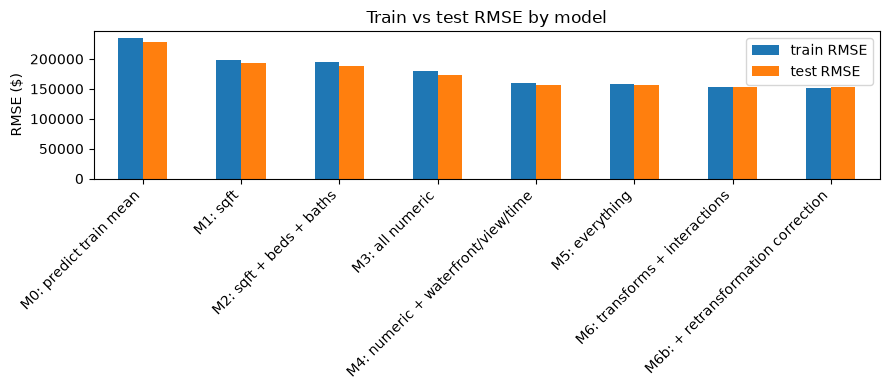

In [ ]:
# Q7: summary of results from Q1-Q6
n_feat = {"M0: predict train mean": 0}
n_feat.update({k: len(v) for k, v in model_features.items()})
n_feat["M6: transforms + interactions"] = X2.shape[1]
n_feat["M6b: + retransformation correction"] = X2.shape[1]

summary = results_q6.copy()
summary["# features"] = pd.Series(n_feat)
summary["test/train RMSE ratio"] = summary["test RMSE"] / summary["train RMSE"]
display(summary.round(3))

summary[["train RMSE", "test RMSE"]].plot.bar(figsize=(9, 4))
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE ($)")
plt.title("Train vs test RMSE by model")
plt.tight_layout()
plt.show()

alpha (min CV error): 0.0002453287754266793   alpha (1-SE rule): 0.004929226720661532


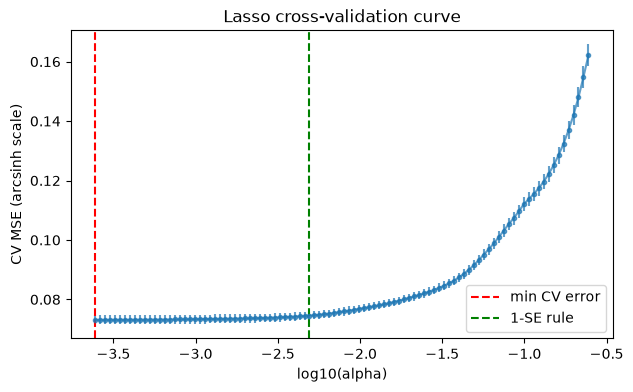


M8a: Lasso (min-CV alpha): kept 55 of 58 features
Dropped: ['house_square_feet', 'wf_WF River', 'month_9']

M8b: Lasso (1-SE alpha): kept 40 of 58 features
Dropped: ['paneling', 'wf_WF River', 'wf_WF Stream/Creek', 'hvac_Hot Water Baseboard', 'roof_Built Up Rock', 'roof_Preformed Metal', 'month_7', 'month_8', 'log_sqft_c_sq', 'yb_c', 'has_basement', 'has_garage', 'has_attic', 'has_fireplace', 'logsqft_x_baths', 'logsqft_x_beds', 'logsqft_x_waterfront', 'yb_x_logsqft']
house_square_feet              0.1329
wf_WF Salt                     0.0687
log_sqft_c                     0.0588
wf_WF Lake                     0.0438
attached_garage_square_feet    0.0427
basement_square_feet           0.0380
view_score                     0.0341
log_basement                   0.0331
month_1                       -0.0237
hvac_Heat Pump                 0.0226
bathrooms                      0.0204
year_built                     0.0200
fireplaces                     0.0169
ext_Frame Vinyl               -0

,train RMSE,test RMSE,train R2,test R2,CV RMSE,RMSE gap (test-train)
M0: predict train mean,234454.953,228643.696,0.000,-0.000,NaN,-5811.257
M1: sqft,198257.974,192512.926,0.285,0.291,196672.618,-5745.049
M2: sqft + beds + baths,195607.099,188959.616,0.304,0.317,194031.853,-6647.483
M3: all numeric,179472.264,173151.093,0.414,0.426,178183.645,-6321.171
M4: numeric + waterfront/view/time,159460.886,156396.711,0.537,0.532,158847.815,-3064.175
M5: everything,157491.131,155682.225,0.549,0.536,157579.317,-1808.907
M6: transforms + interactions,152349.940,153943.776,0.578,0.547,154447.121,1593.836
M6b: + retransformation correction,151215.334,153078.626,0.584,0.552,153666.598,1863.291
M8a: Lasso (min-CV alpha),151770.936,153056.076,0.581,0.552,NaN,1285.140
M8b: Lasso (1-SE alpha),155408.746,155125.669,0.561,0.540,NaN,-283.077


In [ ]:
# Q8
from sklearn.linear_model import LassoCV, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The Lasso penalty depends on feature scale, so standardize first (inside the pipeline,
# so scaling is learned from training data only). Alpha is chosen by 5-fold CV on training data.
lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, max_iter=50000, random_state=42, n_jobs=-1),
)
lasso_cv.fit(X2_train, y_train_t)
cv_model = lasso_cv[-1]

# Two choices for alpha:
#  a) alpha with the lowest cross-validated error
#  b) largest alpha whose CV error is within one standard error of the minimum
mean_mse = cv_model.mse_path_.mean(axis=1)
se_mse = cv_model.mse_path_.std(axis=1) / np.sqrt(cv_model.mse_path_.shape[1])
best = np.argmin(mean_mse)
alpha_1se = max(a for a, m in zip(cv_model.alphas_, mean_mse) if m <= mean_mse[best] + se_mse[best])
print("alpha (min CV error):", cv_model.alpha_, "  alpha (1-SE rule):", alpha_1se)

# CV curve
plt.figure(figsize=(7, 4))
plt.errorbar(np.log10(cv_model.alphas_), mean_mse, yerr=se_mse, fmt="o-", ms=3, alpha=0.7)
plt.axvline(np.log10(cv_model.alpha_), color="red", ls="--", label="min CV error")
plt.axvline(np.log10(alpha_1se), color="green", ls="--", label="1-SE rule")
plt.xlabel("log10(alpha)")
plt.ylabel("CV MSE (arcsinh scale)")
plt.title("Lasso cross-validation curve")
plt.legend()
plt.show()

lasso_1se = make_pipeline(StandardScaler(), Lasso(alpha=alpha_1se, max_iter=50000))
lasso_1se.fit(X2_train, y_train_t)

def lasso_row(mdl):
    tr_t, te_t = mdl.predict(X2_train), mdl.predict(X2_test)
    f = make_to_price(y_train_t - tr_t, USE_SMEARING)
    return {**row(f(tr_t), f(te_t)), "CV RMSE": np.nan}

lasso_models = {"M8a: Lasso (min-CV alpha)": lasso_cv, "M8b: Lasso (1-SE alpha)": lasso_1se}
for label, mdl in lasso_models.items():
    c = pd.Series(mdl[-1].coef_, index=X2.columns)
    print(f"\n{label}: kept {(c != 0).sum()} of {len(c)} features")
    print("Dropped:", list(c[c == 0].index))
    if "1-SE" in label:
        print(c[c != 0].sort_values(key=abs, ascending=False).round(4).to_string())

lasso_rows = pd.DataFrame([lasso_row(m) for m in lasso_models.values()], index=list(lasso_models))
results_q8 = pd.concat([results_q6, lasso_rows])
results_q8["RMSE gap (test-train)"] = results_q8["test RMSE"] - results_q8["train RMSE"]
display(results_q8.round(3))

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

AI helped improve our Phase 1 solution by identifying certain issues in the code and suggesting ways to make our models more reliable. The biggest improvement we saw was it removing redundant variables that could cause multicollinearity. We also ended up improving the data cleaning process, used a price stratified train test split, and added cross validation to compare models more carefully. However, we felt that some of the suggestions given did not add much to the solution. A few of the suggestions made the code too complicated without adding much benefit. To verify the final solution we looked at the feature matrix for redundant variables. We compared training and test RMSE and R² values. We also used cross validation to evaluate the performance of the model. Finally, we looked at how the models looked visually in comparision to the models from phase 1. A concern that we have is that the model might lead to overfitting as it is more complicated, making it unknown as to how it is going to perform if given new data.
